# Comparing beta-update rules -- g-and-k

This notebook runs the conjugate beta calibration (general posterior
calibration, GPC) on the **g-and-k** bundle and compares calibration methods
for ``log(beta)``:

All three share the same bootstrap stream (same seed) and the same posterior,
so they differ only in how ``log(beta)`` is updated.

> **Data:** `examples/experimental/data/test_gnk.pkl` + `test_gnk.pt` model checkpoint.
> Build them with
> `python -m nsm_bayes.experiments.test_data.make_test_data_gnk`.


## 0. Imports and helpers

In [8]:

import contextlib
import io
import pickle
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2

warnings.filterwarnings("ignore")

from nsm_bayes.models.conjugate import EnergyBasedModel
from nsm_bayes.models.conjugate.conj_posterior import ConjugatePosterior

# The experimental beta-update step functions (GPC matches the library exactly).
import beta_update as bu

# Ordered step functions to compare; LABEL maps each to its short display name.
STEP_FNS = [bu.step_gpc, bu.step_gd, bu.step_rm]
LABEL = {fn: getattr(fn, "label", fn.__name__) for fn in STEP_FNS}

QUIET = contextlib.redirect_stdout(io.StringIO())

def run_quiet(fn, *args, **kwargs):
    """Run `fn`, suppressing its stdout, and return its result."""
    with QUIET:
        return fn(*args, **kwargs)

def load_model(b, ckpt):
    return EnergyBasedModel(d_x=b["d_x"], d_theta=b["d_theta"],
                            hidden_dim=b["config"]["hidden_dim"]).load_checkpoint(ckpt)

def load_posterior(b, ckpt):
    return ConjugatePosterior(load_model(b, ckpt),
                              b["prior_mean"], b["prior_cov"],
                              robust=True,
                              weight_type="imq")

## 1. Load the bundle

In [9]:
path = "data/test_gnk.pkl"
ckpt = "data/test_gnk.pt"

try:
    with open(path, "rb") as fh:
        b = pickle.load(fh)
    cfg = b["config"]
    beta_min = cfg.get("beta_min_case1", 0.01)
    target = 1.0 - cfg["alpha"]
    x = b["x_obs_mis"]
    d = b["d_theta"]

    print(f"experiment  : {b['experiment']} (rep {b['rep']}), seed {b['seed']}")
    print(f"d_x         : {b['d_x']}, d_theta: {b['d_theta']}")
    print(f"x_obs_mis   : {tuple(x.shape)}, theta_true: {b['theta_true']}")
    print(f"B={cfg['B']}, T={cfg['T']}, alpha={cfg['alpha']}, "
        f"beta0={cfg['beta_base_case1']}, beta_min={beta_min}")
    print(f"meta        : {b['meta']}")
except:
    raise SystemExit(
            f"bundle not found: {path} or {ckpt}\n"
            f"Run:  python -m nsm_bayes.experiments.test_data.make_test_data_gnk"
        )

experiment  : gnk (rep 0), seed 1
d_x         : 1, d_theta: 4
x_obs_mis   : (60, 1), theta_true: tensor([ 1.0000,  0.5000,  1.0000, -1.0000])
B=100, T=20, alpha=0.05, beta0=0.1, beta_min=0.01
meta        : {'source': 'generated from scratch (configs/gnk.yaml)', 'num_samples': 8000, 'n_obs': 60, 'outlier_noise_std': 0.001, 'created': '2026-11-06T08:58:20.754958+00:00', 'train_secs': 133.551442861557}


## 2. Run the three step functions

Every step function runs on the same bundle with the **same seed** (identical bootstrap stream); the only difference is how ``log(beta)`` is updated. 

In [15]:
SEED = 100
LR = 0.2
START_GRID = np.logspace(-4, 3, 8)   # grid start for the iterative rules (7 points + 3 bisections)
FIXED_GRID = np.logspace(-4, 1, 10)  # the grid-only method: 10 points, closest coverage wins

# label -> (step function, or None for the grid-only method; initial beta; extra keyword arguments)
METHODS = {
    #"gpc":    (bu.step_gpc,    START_GRID, {}),
    #"gd":     (bu.step_gd,     START_GRID, {"lr": LR}),
    #"rm":     (bu.step_rm,     START_GRID, {}),
   # "bisect": (bu.step_bisect, START_GRID, {}),
    "grid":   (None,           FIXED_GRID, {}),
}
COMMON = dict(target_coverage=target, num_iterations=cfg["T"], num_bootstraps=cfg["B"],
              max_log_step=0.25, beta_min=beta_min, seed=SEED)

results = {}
posterior = load_posterior(b, ckpt)
for label, (step_fn, beta0, kwargs) in METHODS.items():
    t0 = time.time()
    np.random.seed(SEED)  # with robust=True the MCD estimator draws from numpy's global RNG
    if step_fn is None:
        results[label] = run_quiet(bu.run_grid_search, x, posterior, beta0, **COMMON, **kwargs)
    else:
        results[label] = run_quiet(bu.run_update_rule, step_fn, x, posterior, beta0, **COMMON, **kwargs)
    res = results[label]
    n_evals = len(res["history"]["coverages"]) + len(res.get("grid", {}).get("betas", []))
    print(f"{label:6s} -> beta={res['beta']:.6f}  ({n_evals} coverage evaluations, {time.time() - t0:.1f}s)")

LABEL = {label: label for label in results}  # later cells look up LABEL[key] for each results key

grid   -> beta=0.059948  (10 coverage evaluations, 13.9s)


## 5. Coverage trajectories

The empirical bootstrap coverage `c_t` that drives each rule; the dashed line is the target.

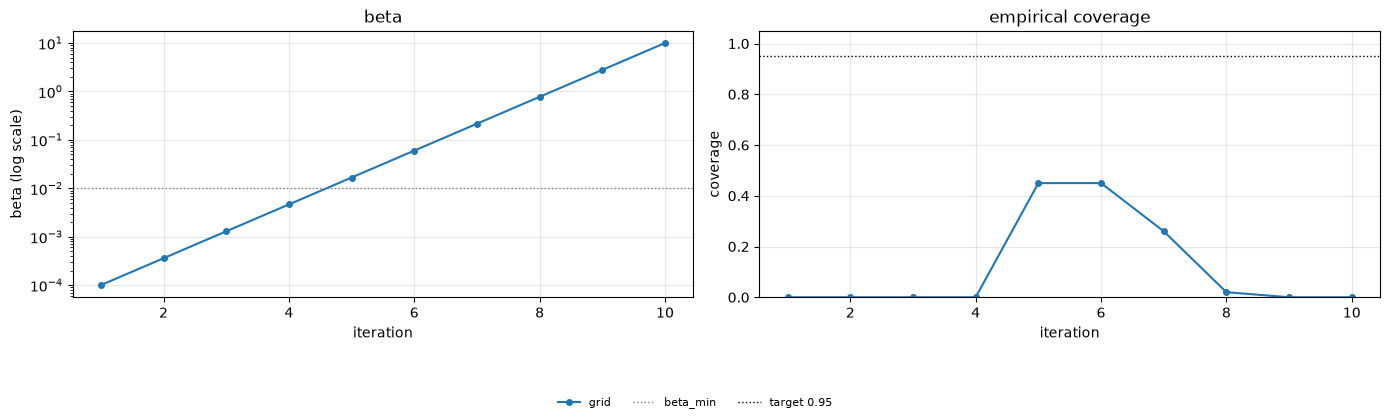

In [16]:
fig, (ax_b, ax_c) = plt.subplots(1, 2, figsize=(14, 4.2))
SETS = [(results, "o", "-", "")]
methods = list(dict.fromkeys(list(results) + list(results)))
color = {m: f"C{i}" for i, m in enumerate(methods)}  # same colour for a method in both sets

for res_set, marker, ls, suffix in SETS:
    for key, r in res_set.items():
        t = np.arange(1, len(r["history"]["betas"]) + 1)  # per method: the grid method has fewer points
        name = LABEL.get(key, getattr(key, "__name__", key)) + suffix
        ax_b.semilogy(t, r["history"]["betas"], marker=marker, ms=4, ls=ls, color=color[key], label=name)
        ax_c.plot(t, r["history"]["coverages"], marker=marker, ms=4, ls=ls, color=color[key], label=name)

ax_b.axhline(beta_min, ls=":", c="gray", lw=1, label="beta_min")
ax_b.set_title("beta"); ax_b.set_xlabel("iteration"); ax_b.set_ylabel("beta (log scale)")
ax_b.grid(alpha=0.3)
ax_c.axhline(target, ls=":", c="k", lw=1, label=f"target {target}")
ax_c.set_ylim(0, 1.05); ax_c.set_title("empirical coverage")
ax_c.set_xlabel("iteration"); ax_c.set_ylabel("coverage"); ax_c.grid(alpha=0.3)

handles, labels = ax_b.get_legend_handles_labels()
h_c, l_c = ax_c.get_legend_handles_labels()
fig.legend(handles + h_c[-1:], labels + l_c[-1:], loc="lower center", ncol=6, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.14, 1, 1)); plt.show()

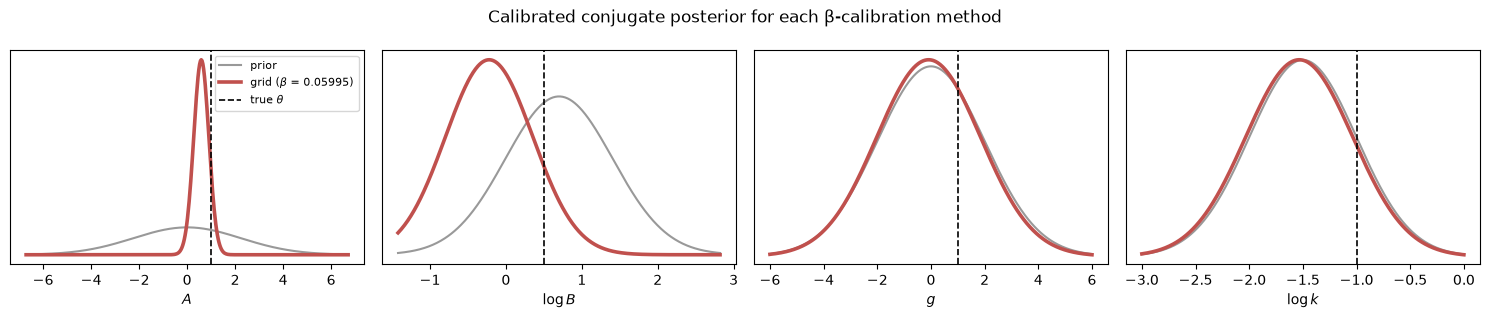

In [17]:
# ---- Calibrated posteriors from every beta-calibration method, vs prior and theta_true ----
theta_true = b["theta_true"].numpy()
prior_mu = b["prior_mean"].numpy()
prior_sd = np.sqrt(np.diag(b["prior_cov"].numpy()))
labels = {"sir": [r"$\log\beta$", r"$\log\gamma$", r"$\mathrm{logit}\,\rho$", r"$\log I_0$"],
          "gnk": [r"$A$", r"$\log B$", r"$g$", r"$\log k$"]}[b["experiment"]]
colors = ["#C0504D", "#4F81BD", "#9BBB59", "#8064A2", "#F79646"]

posts = []  # (method, beta, posterior mean, posterior sd) as numpy arrays
for key, res in results.items():
    mu_n, Sigma_n = posterior.calibrated_posterior(x, res["beta"])
    name = str(getattr(key, "__name__", key)).removeprefix("step_")
    posts.append((name, res["beta"], mu_n.numpy(), np.sqrt(np.diag(Sigma_n.numpy()))))

fig, axes = plt.subplots(1, d, figsize=(15, 3.2))
for k, ax in enumerate(axes):
    grid = np.linspace(prior_mu[k] - 3 * prior_sd[k], prior_mu[k] + 3 * prior_sd[k], 400)
    curves = [(prior_mu[k], prior_sd[k], "prior", "0.6", 1.5)]
    curves += [(mu_n[k], sd_n[k], fr"{name} ($\beta$ = {beta:.4g})", colors[i % len(colors)], 2.6 - 0.6 * i)
               for i, (name, beta, mu_n, sd_n) in enumerate(posts)]
    for m, s, lab, col, lw in curves:
        dens = np.exp(-0.5 * ((grid - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
        ax.plot(grid, dens, color=col, lw=lw, label=lab)
    ax.axvline(theta_true[k], color="k", ls="--", lw=1.2, label=r"true $\theta$")
    ax.set_xlabel(labels[k]); ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle("Calibrated conjugate posterior for each β-calibration method")
plt.tight_layout(); plt.show()